# Telecom Customer Churn Prediction

## Machine Learning Classification Project

Customer churn is a practical business problem: a telecom company wants to identify customers who may leave so that retention teams can investigate the situation and take appropriate action.

This project uses historical customer information to build a binary classification system that predicts:

- **Churn = 1:** customer left
- **Churn = 0:** customer stayed

The workflow covers the complete machine-learning process:

**Data → Understanding → Cleaning → Exploration → Feature Engineering → Training → Evaluation → Prediction**

> **Project note:** The Excel dataset is expected to be stored in the same folder as this notebook. The notebook accepts the original dataset filename and a shorter common filename so it remains convenient to reuse as a portfolio project.

## Project goals

By the end of this project, we will:

1. Understand the structure and quality of the customer data.
2. Clean the data and document the decisions made.
3. Explore relationships between customer characteristics and churn.
4. Convert raw customer information into model-ready numerical features.
5. Train two classification models.
6. Evaluate both models on unseen test data.
7. Select a model using a clearly defined metric.
8. Use the selected model to make predictions for new customers.

The emphasis is on **understanding the reasoning behind each stage**, not just producing predictions.

In [ ]:
# Environment setup

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Environment ready.")

Environment ready.


## 1. Data Loading and Understanding

The first stage is to inspect the raw dataset before making any changes.

We want to answer:

- How many customers and variables are present?
- What are the column names and data types?
- What do the important variables represent?
- What does the target variable look like?

In [ ]:
# Load the Excel dataset

DATA_CANDIDATES = [
    "WA_Fn-UseC_-Telco-Customer-Churn.xlsx",  # original dataset filename
    "Telco-Customer-Churn.xlsx",              # convenient portfolio filename
]

data_file = next(
    (Path(name) for name in DATA_CANDIDATES if Path(name).exists()),
    None
)

if data_file is None:
    raise FileNotFoundError(
        "Excel dataset not found. Place either "
        "'WA_Fn-UseC_-Telco-Customer-Churn.xlsx' or "
        "'Telco-Customer-Churn.xlsx' in the same folder as this notebook."
    )

df = pd.read_excel(data_file)

print(f"Loaded: {data_file.name}")
print(f"Dataset shape: {df.shape}")
display(df.head())

Loaded: Telco-Customer-Churn.xlsx
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
# Dataset structure

print("Column names:")
for number, column in enumerate(df.columns, start=1):
    print(f"{number:2}. {column}")

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nNumerical summary:")
display(df.describe().T)

Column names:
 1. customerID
 2. gender
 3. SeniorCitizen
 4. Partner
 5. Dependents
 6. tenure
 7. PhoneService
 8. MultipleLines
 9. InternetService
10. OnlineSecurity
11. OnlineBackup
12. DeviceProtection
13. TechSupport
14. StreamingTV
15. StreamingMovies
16. Contract
17. PaperlessBilling
18. PaymentMethod
19. MonthlyCharges
20. TotalCharges
21. Churn

Data types:


,Data Type
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str



Numerical summary:


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [ ]:
# Target variable

target_counts = df["Churn"].value_counts(dropna=False)

print("Target variable: Churn")
print("Yes = customer left")
print("No  = customer stayed")
display(target_counts.to_frame("Customer Count"))

print("Target percentages:")
display(
    (df["Churn"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
    .to_frame("Percentage")
)

Target variable: Churn
Yes = customer left
No  = customer stayed


,Customer Count
Churn,
No,5174
Yes,1869


Target percentages:


,Percentage
Churn,
No,73.46
Yes,26.54


### Important variables

| Variable | Meaning |
|---|---|
| `customerID` | Unique identifier for a customer; useful for identification but not as a predictive feature. |
| `gender` | Customer gender. |
| `SeniorCitizen` | Whether the customer is a senior citizen, represented as 0/1. |
| `Partner` | Whether the customer has a partner. |
| `Dependents` | Whether the customer has dependents. |
| `tenure` | Number of months the customer has remained with the company. |
| `InternetService` | Internet service type. |
| `Contract` | Contract type: month-to-month, one year, or two year. |
| `PaymentMethod` | Customer payment method. |
| `MonthlyCharges` | Current monthly service charge. |
| `TotalCharges` | Total amount charged to the customer. |
| `Churn` | Target: whether the customer left the company. |

In [ ]:
# Data understanding summary

missing_total = int(df.isna().sum().sum())
duplicate_total = int(df.duplicated().sum())
churn_rate = (df["Churn"].eq("Yes").mean() * 100)

print("Data understanding summary")
print("-" * 28)
print(f"Customers: {len(df):,}")
print(f"Features before cleaning: {df.shape[1]:,}")
print(f"Missing cells detected: {missing_total:,}")
print(f"Exact duplicate rows: {duplicate_total:,}")
print(f"Observed churn rate: {churn_rate:.2f}%")
print(
    "\nTakeaway: The raw data has now been profiled before any cleaning or "
    "model training decisions are made."
)

Data understanding summary
----------------------------
Customers: 7,043
Features before cleaning: 21
Missing cells detected: 0
Exact duplicate rows: 0
Observed churn rate: 26.54%

Takeaway: The raw data has now been profiled before any cleaning or model training decisions are made.


## 2. Data Preprocessing

Machine-learning models require consistent and usable input.

The cleaning process checks for:

- missing values,
- duplicate records,
- incorrect data types,
- unnecessary identifiers, and
- other obvious data-quality issues.

Each decision is kept explicit so that the transformation from raw data to modeling data can be traced.

In [ ]:
# Check data quality before cleaning

missing_before = df.isna().sum()
print("Columns containing missing values:")
display(missing_before[missing_before > 0].to_frame("Missing Values"))

print(f"Exact duplicate rows: {df.duplicated().sum():,}")

print("\nData types before cleaning:")
display(df.dtypes.to_frame("Data Type"))

Columns containing missing values:


,Missing Values


Exact duplicate rows: 0

Data types before cleaning:


,Data Type
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


In [ ]:
# Convert TotalCharges to numeric

df_clean = df.copy()

df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

print("TotalCharges dtype after conversion:", df_clean["TotalCharges"].dtype)
print(
    "Missing TotalCharges after conversion:",
    int(df_clean["TotalCharges"].isna().sum())
)

TotalCharges dtype after conversion: float64
Missing TotalCharges after conversion: 11


### Cleaning decisions

**`TotalCharges` conversion:**  
The column represents a numeric monetary amount, but blank/whitespace values can cause it to be interpreted as text. Converting it to numeric makes the feature usable for modeling; invalid entries become `NaN`.

**Missing values:**  
Rows containing missing values are removed because only a small number of records are affected and the resulting dataset remains sufficiently large for this project.

**Duplicate records:**  
Exact duplicate rows are removed because repeated records can give those observations disproportionate influence during analysis and training.

**`customerID`:**  
This is an identifier, not a meaningful behavioral measurement. It is retained during initial inspection but removed before feature engineering.

In [ ]:
# Apply the cleaning decisions

rows_before = len(df_clean)

missing_rows_removed = int(df_clean.isna().any(axis=1).sum())
df_clean = df_clean.dropna().copy()

duplicate_rows_removed = int(df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates().copy()

if "customerID" in df_clean.columns:
    df_clean = df_clean.drop(columns=["customerID"])

print(f"Rows before cleaning: {rows_before:,}")
print(f"Rows removed for missing values: {missing_rows_removed:,}")
print(f"Duplicate rows removed: {duplicate_rows_removed:,}")
print(f"Final cleaned shape: {df_clean.shape}")
print(f"Remaining missing cells: {int(df_clean.isna().sum().sum()):,}")
print(f"Remaining duplicate rows: {int(df_clean.duplicated().sum()):,}")
print(f"TotalCharges dtype: {df_clean['TotalCharges'].dtype}")

Rows before cleaning: 7,043
Rows removed for missing values: 11
Duplicate rows removed: 0
Final cleaned shape: (7032, 20)
Remaining missing cells: 0
Remaining duplicate rows: 22
TotalCharges dtype: float64


In [ ]:
# Preprocessing summary

rows_removed = rows_before - len(df_clean)

print("Preprocessing summary")
print("-" * 24)
print(f"Rows retained: {len(df_clean):,} ({len(df_clean) / rows_before:.2%})")
print(f"Total rows removed: {rows_removed:,}")
print("Identifier removed: customerID")
print("Numeric conversion applied: TotalCharges")
print(f"Missing cells remaining: {int(df_clean.isna().sum().sum())}")
print(f"Duplicate rows remaining: {int(df_clean.duplicated().sum())}")
print(
    "\nTakeaway: The modeling dataset is now free of missing values and "
    "exact duplicate rows, with the identifier removed and monetary data stored numerically."
)

Preprocessing summary
------------------------
Rows retained: 7,032 (99.84%)
Total rows removed: 11
Identifier removed: customerID
Numeric conversion applied: TotalCharges
Missing cells remaining: 0
Duplicate rows remaining: 22

Takeaway: The modeling dataset is now free of missing values and exact duplicate rows, with the identifier removed and monetary data stored numerically.


## 3. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is used to discover patterns and relationships in the cleaned data before modeling.

The analysis below focuses on:

- overall churn distribution,
- contract type,
- internet service,
- customer tenure, and
- monthly charges.

The observations describe relationships in this dataset; they should not be interpreted as proof of causation.

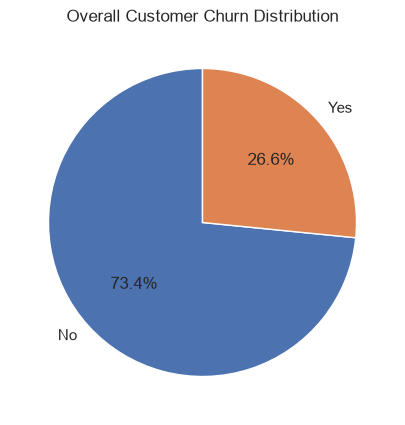

,Customer Count,Percentage
Churn,,
No,5163,73.42
Yes,1869,26.58


In [ ]:
# Overall churn distribution

churn_counts = df_clean["Churn"].value_counts()

plt.figure(figsize=(7, 5))
plt.pie(
    churn_counts.values,
    labels=churn_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Overall Customer Churn Distribution")
plt.show()

display(
    pd.DataFrame({
        "Customer Count": churn_counts,
        "Percentage": (churn_counts / len(df_clean) * 100).round(2)
    })
)

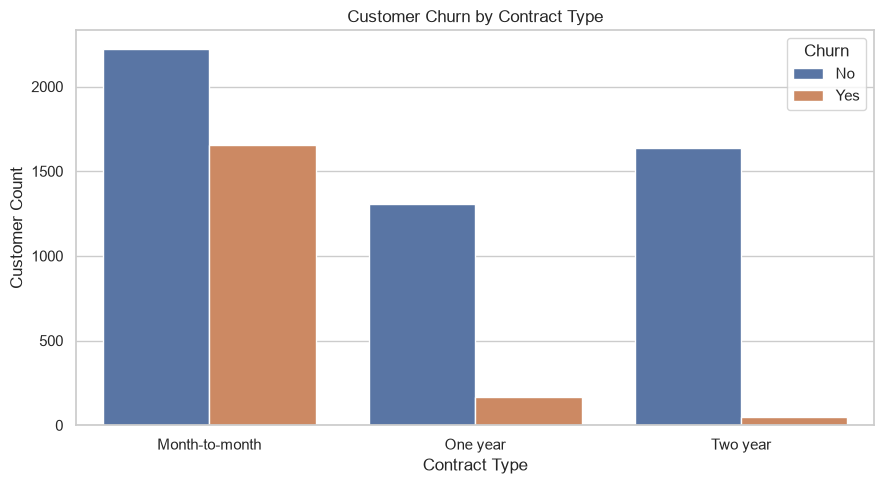

Churn percentage within each contract type:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.72,11.28
Two year,97.15,2.85


In [ ]:
# Contract type vs churn

contract_churn = (
    pd.crosstab(df_clean["Contract"], df_clean["Churn"], normalize="index") * 100
)

plt.figure(figsize=(9, 5))
sns.countplot(data=df_clean, x="Contract", hue="Churn")
plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Customer Count")
plt.tight_layout()
plt.show()

print("Churn percentage within each contract type:")
display(contract_churn.round(2))

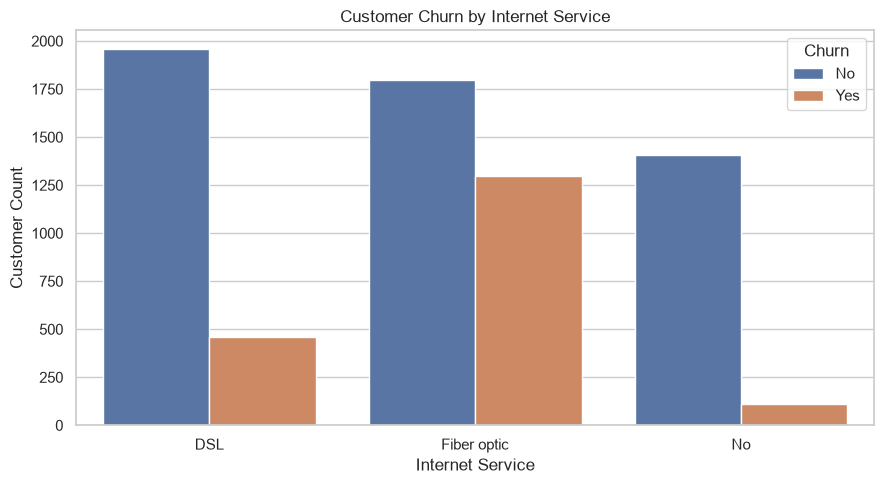

Churn percentage within each internet-service category:


Churn,No,Yes
InternetService,,
DSL,81.00,19.00
Fiber optic,58.11,41.89
No,92.57,7.43


In [ ]:
# Internet service vs churn

internet_churn = (
    pd.crosstab(df_clean["InternetService"], df_clean["Churn"], normalize="index") * 100
)

plt.figure(figsize=(9, 5))
sns.countplot(data=df_clean, x="InternetService", hue="Churn")
plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Customer Count")
plt.tight_layout()
plt.show()

print("Churn percentage within each internet-service category:")
display(internet_churn.round(2))

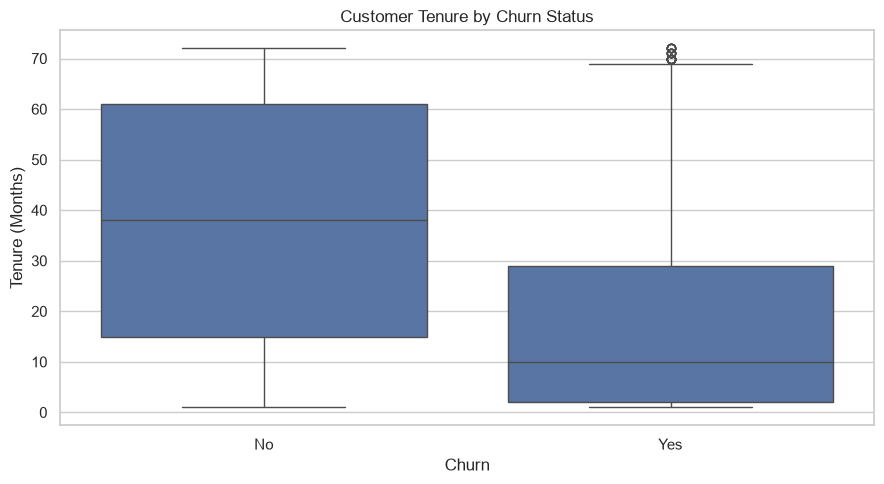

,Median Tenure,Average Tenure
Churn,,
No,38.0,37.65
Yes,10.0,17.98


In [ ]:
# Tenure vs churn

plt.figure(figsize=(9, 5))
sns.boxplot(data=df_clean, x="Churn", y="tenure")
plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

tenure_summary = (
    df_clean.groupby("Churn")["tenure"]
    .agg(["median", "mean"])
    .round(2)
    .rename(columns={"median": "Median Tenure", "mean": "Average Tenure"})
)

display(tenure_summary)

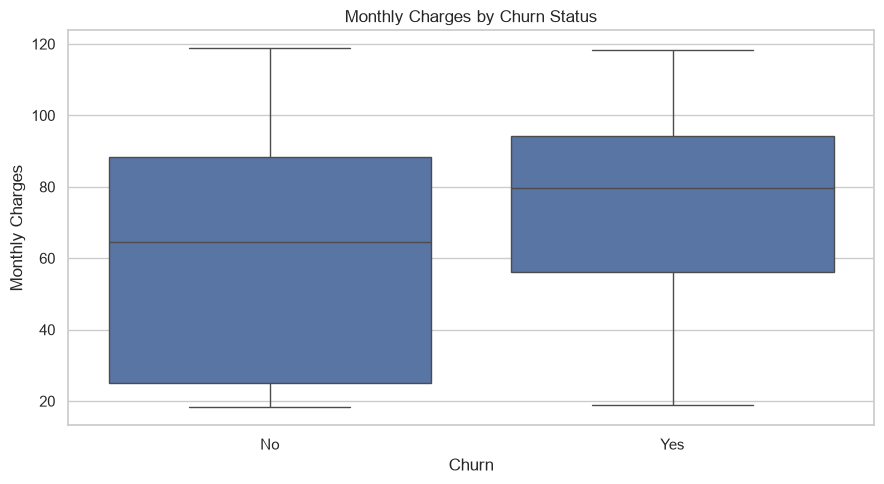

,Average Monthly Charges
Churn,
No,61.31
Yes,74.44


In [ ]:
# Monthly charges vs churn

plt.figure(figsize=(9, 5))
sns.boxplot(data=df_clean, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

monthly_summary = (
    df_clean.groupby("Churn")["MonthlyCharges"]
    .mean()
    .round(2)
    .to_frame("Average Monthly Charges")
)

display(monthly_summary)

In [ ]:
# EDA summary: derive observations directly from the computed tables

churned_contract_rates = contract_churn["Yes"].sort_values(ascending=False)
churned_internet_rates = internet_churn["Yes"].sort_values(ascending=False)

median_tenure_yes = df_clean.loc[df_clean["Churn"] == "Yes", "tenure"].median()
median_tenure_no = df_clean.loc[df_clean["Churn"] == "No", "tenure"].median()

avg_monthly_yes = df_clean.loc[df_clean["Churn"] == "Yes", "MonthlyCharges"].mean()
avg_monthly_no = df_clean.loc[df_clean["Churn"] == "No", "MonthlyCharges"].mean()

print("EDA summary")
print("-" * 18)
print(f"Overall churn rate: {df_clean['Churn'].eq('Yes').mean():.2%}")
print(
    f"Highest contract-level churn rate: {churned_contract_rates.index[0]} "
    f"({churned_contract_rates.iloc[0]:.2f}%)"
)
print(
    f"Lowest contract-level churn rate: {churned_contract_rates.index[-1]} "
    f"({churned_contract_rates.iloc[-1]:.2f}%)"
)
print(
    f"Highest internet-service churn rate: {churned_internet_rates.index[0]} "
    f"({churned_internet_rates.iloc[0]:.2f}%)"
)
print(f"Median tenure — churned: {median_tenure_yes:.1f} months")
print(f"Median tenure — retained: {median_tenure_no:.1f} months")
print(f"Average monthly charges — churned: {avg_monthly_yes:.2f}")
print(f"Average monthly charges — retained: {avg_monthly_no:.2f}")

print(
    "\nTakeaway: These summaries identify dataset-level relationships that can "
    "help explain churn patterns. They are descriptive associations, not causal conclusions."
)

EDA summary
------------------
Overall churn rate: 26.58%
Highest contract-level churn rate: Month-to-month (42.71%)
Lowest contract-level churn rate: Two year (2.85%)
Highest internet-service churn rate: Fiber optic (41.89%)
Median tenure — churned: 10.0 months
Median tenure — retained: 38.0 months
Average monthly charges — churned: 74.44
Average monthly charges — retained: 61.31

Takeaway: These summaries identify dataset-level relationships that can help explain churn patterns. They are descriptive associations, not causal conclusions.


## 4. Feature Engineering and Encoding

The raw dataset contains both numerical and categorical variables. Most classification algorithms require numerical input, so categorical variables must be represented numerically.

The transformations used here are:

- binary `Yes/No` fields → `0/1`,
- service-related `No internet service` / `No phone service` → `No`,
- multi-category variables → one-hot encoding,
- `Churn` → binary target,
- separate the predictors (`X`) from the target (`y`).

`customerID` is already removed because it is an identifier rather than a predictive feature.

In [ ]:
# Encode the target and categorical predictors

df_encoded = df_clean.copy()

# Target
df_encoded["Churn"] = df_encoded["Churn"].map({"Yes": 1, "No": 0})

# Binary Yes/No predictors
binary_cols = [
    "Partner",
    "Dependents",
    "PhoneService",
    "PaperlessBilling",
]

for col in binary_cols:
    df_encoded[col] = df_encoded[col].map({"Yes": 1, "No": 0})

# Service columns: absence of the service is represented as No
service_cols = [
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
]

for col in service_cols:
    df_encoded[col] = (
        df_encoded[col]
        .replace({
            "No internet service": "No",
            "No phone service": "No",
        })
        .map({"Yes": 1, "No": 0})
    )

# Nominal variables
nominal_cols = [
    "gender",
    "InternetService",
    "Contract",
    "PaymentMethod",
]

df_encoded = pd.get_dummies(
    df_encoded,
    columns=nominal_cols,
    drop_first=True,
    dtype=int,
)

X = df_encoded.drop(columns=["Churn"])
y = df_encoded["Churn"]

print("Feature matrix X shape:", X.shape)
print("Target vector y shape:", y.shape)

non_numeric = X.select_dtypes(exclude=np.number).columns.tolist()
print("\nNon-numeric columns remaining in X:", non_numeric if non_numeric else "None")

display(X.head())

Feature matrix X shape: (7032, 23)
Target vector y shape: (7032,)

Non-numeric columns remaining in X: None


,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,MonthlyCharges,TotalCharges,gender_Male,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,0,1,0,0,0,1,0,0,0,0,1,29.85,29.85,0,0,0,0,0,0,1,0
1,0,0,0,34,1,0,1,0,1,0,0,0,0,56.95,1889.50,1,0,0,1,0,0,0,1
2,0,0,0,2,1,0,1,1,0,0,0,0,1,53.85,108.15,1,0,0,0,0,0,0,1
3,0,0,0,45,0,0,1,0,1,1,0,0,0,42.30,1840.75,1,0,0,1,0,0,0,0
4,0,0,0,2,1,0,0,0,0,0,0,0,1,70.70,151.65,0,1,0,0,0,0,1,0


### Why one-hot encoding uses `drop_first=True`

A categorical variable with several categories can be represented by indicator columns. Keeping one category as the reference and encoding the others avoids a redundant set of dummy variables, which is useful for linear models such as Logistic Regression.

In [ ]:
# Feature engineering summary

print("Feature engineering summary")
print("-" * 28)
print(f"Model input rows: {X.shape[0]:,}")
print(f"Model input features: {X.shape[1]:,}")
print("Target encoding: Yes → 1, No → 0")
print("Binary categorical fields: encoded as 0/1")
print("Multi-category fields: one-hot encoded")
print(f"All X features numeric: {X.select_dtypes(exclude=np.number).shape[1] == 0}")
print(f"Target values present: {sorted(y.unique().tolist())}")

print(
    "\nTakeaway: The customer records are now represented as a numerical feature "
    "matrix that can be supplied to classification algorithms."
)

Feature engineering summary
----------------------------
Model input rows: 7,032
Model input features: 23
Target encoding: Yes → 1, No → 0
Binary categorical fields: encoded as 0/1
Multi-category fields: one-hot encoded
All X features numeric: True
Target values present: [0, 1]

Takeaway: The customer records are now represented as a numerical feature matrix that can be supplied to classification algorithms.


## 5. Training and Testing

A model should be evaluated on data it did not see during training.

We therefore split the dataset into:

- **80% training data** — used to learn patterns.
- **20% test data** — kept aside for final evaluation.

`stratify=y` preserves approximately the same churn proportion in both subsets.

For Logistic Regression, numerical variables are standardized. The scaler is fitted **only on the training data**, which prevents information from the test set leaking into the training process.

Two classifiers are trained:

1. **Logistic Regression** — a linear probabilistic classifier.
2. **Random Forest** — an ensemble of decision trees.

In [ ]:
# Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print(f"Training samples: {len(X_train):,}")
print(f"Testing samples:  {len(X_test):,}")

split_summary = pd.DataFrame({
    "Training %": y_train.value_counts(normalize=True).sort_index() * 100,
    "Testing %": y_test.value_counts(normalize=True).sort_index() * 100,
})
split_summary.index = ["No Churn (0)", "Churn (1)"]

display(split_summary.round(2))

Training samples: 5,625
Testing samples:  1,407


,Training %,Testing %
No Churn (0),73.42,73.42
Churn (1),26.58,26.58


In [ ]:
# Standardize numerical variables using training data only

numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

scaler = StandardScaler()

X_train_model = X_train.copy()
X_test_model = X_test.copy()

X_train_model[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_model[numeric_cols] = scaler.transform(X_test[numeric_cols])

print("Scaled numerical features:", numeric_cols)
print("Scaler fitted on training data only.")

Scaled numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Scaler fitted on training data only.


In [ ]:
# Train Logistic Regression and Random Forest

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
)

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
)

logistic_model.fit(X_train_model, y_train)
random_forest_model.fit(X_train_model, y_train)

print("Training completed.")
print("- Logistic Regression")
print("- Random Forest")

Training completed.
- Logistic Regression
- Random Forest


In [ ]:
# Training summary

print("Training summary")
print("-" * 19)
print(f"Training rows: {len(X_train):,}")
print(f"Testing rows: {len(X_test):,}")
print(f"Training features: {X_train.shape[1]:,}")
print("Split ratio: 80% training / 20% testing")
print("Stratification: enabled")
print("Scaling leakage protection: scaler fitted only on training data")

print(
    "\nTakeaway: Both classifiers have been trained without using the test-set "
    "outcomes during fitting."
)

Training summary
-------------------
Training rows: 5,625
Testing rows: 1,407
Training features: 23
Split ratio: 80% training / 20% testing
Stratification: enabled
Scaling leakage protection: scaler fitted only on training data

Takeaway: Both classifiers have been trained without using the test-set outcomes during fitting.


## 6. Model Evaluation

The models are evaluated on the unseen test set using four classification metrics:

- **Accuracy** — proportion of all predictions that are correct.
- **Precision** — among predicted churners, the proportion who actually churned.
- **Recall** — among actual churners, the proportion identified by the model.
- **F1-Score** — harmonic mean of precision and recall.

A **confusion matrix** provides the counts of true positives, true negatives, false positives, and false negatives.

For this project, **F1-Score is used as the primary comparison metric** because churn is not perfectly balanced and F1 considers both precision and recall.

In [ ]:
# Generate predictions on the unseen test set

y_pred_lr = logistic_model.predict(X_test_model)
y_pred_rf = random_forest_model.predict(X_test_model)

def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, zero_division=0),
    }

lr_metrics = calculate_metrics(y_test, y_pred_lr)
rf_metrics = calculate_metrics(y_test, y_pred_rf)

comparison = pd.DataFrame(
    [lr_metrics, rf_metrics],
    index=["Logistic Regression", "Random Forest"],
)

print("Test-set performance:")
display(comparison.round(4))

Test-set performance:


,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.8031,0.6483,0.5668,0.6049
Random Forest,0.7918,0.6364,0.5053,0.5633


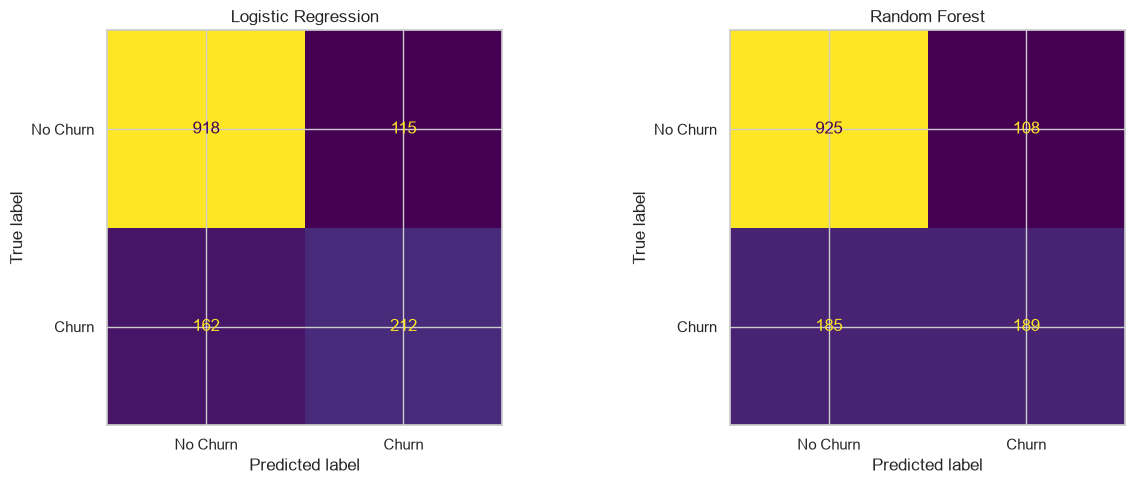

In [ ]:
# Confusion matrices

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred_lr),
    display_labels=["No Churn", "Churn"],
).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred_rf),
    display_labels=["No Churn", "Churn"],
).plot(ax=axes[1], colorbar=False)
axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()

In [ ]:
# Detailed classification reports

print("Logistic Regression")
print("=" * 60)
print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=["No Churn", "Churn"],
        zero_division=0,
    )
)

print("\nRandom Forest")
print("=" * 60)
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["No Churn", "Churn"],
        zero_division=0,
    )
)

Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1033
       Churn       0.65      0.57      0.60       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407


Random Forest
              precision    recall  f1-score   support

    No Churn       0.83      0.90      0.86      1033
       Churn       0.64      0.51      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



In [ ]:
# Objective model comparison and selection

best_model_name = comparison["F1-Score"].idxmax()

if best_model_name == "Logistic Regression":
    selected_model = logistic_model
    selected_model_metrics = lr_metrics
    selected_predictions = y_pred_lr
else:
    selected_model = random_forest_model
    selected_model_metrics = rf_metrics
    selected_predictions = y_pred_rf

metric_winners = comparison.idxmax()

print("Model comparison")
print("-" * 18)
display(comparison.round(4))

print(f"Primary selection metric: F1-Score")
print(f"Selected model: {best_model_name}")

print("\nMetric-by-metric comparison:")
for metric in comparison.columns:
    print(f"- {metric}: {metric_winners[metric]}")

print(
    "\nWhy this model was selected: it achieved the highest test-set F1-Score, "
    "the project's primary comparison metric. The other metrics remain important "
    "because a business may value precision or recall differently depending on "
    "the cost of retention campaigns and missed churners."
)

Model comparison
------------------


,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.8031,0.6483,0.5668,0.6049
Random Forest,0.7918,0.6364,0.5053,0.5633


Primary selection metric: F1-Score
Selected model: Logistic Regression

Metric-by-metric comparison:
- Accuracy: Logistic Regression
- Precision: Logistic Regression
- Recall: Logistic Regression
- F1-Score: Logistic Regression

Why this model was selected: it achieved the highest test-set F1-Score, the project's primary comparison metric. The other metrics remain important because a business may value precision or recall differently depending on the cost of retention campaigns and missed churners.


### Evaluation interpretation

A useful churn system should not be judged by accuracy alone.

- A **false negative** is a customer who churns even though the model predicted no churn.
- A **false positive** is a customer predicted to churn who actually stays.
- Higher **recall** means more actual churners are identified.
- Higher **precision** means churn predictions are more concentrated among real churners.

The model comparison above reports the actual test-set values and identifies the model selected for the application stage using the predefined F1 criterion.

In [ ]:
# Evaluation summary

selected_f1 = comparison.loc[best_model_name, "F1-Score"]
selected_recall = comparison.loc[best_model_name, "Recall"]
selected_precision = comparison.loc[best_model_name, "Precision"]
selected_accuracy = comparison.loc[best_model_name, "Accuracy"]

print("Evaluation summary")
print("-" * 21)
print(f"Selected model: {best_model_name}")
print(f"Accuracy:  {selected_accuracy:.4f}")
print(f"Precision: {selected_precision:.4f}")
print(f"Recall:    {selected_recall:.4f}")
print(f"F1-Score:  {selected_f1:.4f}")

print(
    f"\nTakeaway: {best_model_name} has the highest test-set F1-Score "
    "under the project's predefined comparison rule. The confusion matrix "
    "and the remaining metrics should be considered alongside F1 when judging "
    "how useful the model would be for a real retention process."
)

Evaluation summary
---------------------
Selected model: Logistic Regression
Accuracy:  0.8031
Precision: 0.6483
Recall:    0.5668
F1-Score:  0.6049

Takeaway: Logistic Regression has the highest test-set F1-Score under the project's predefined comparison rule. The confusion matrix and the remaining metrics should be considered alongside F1 when judging how useful the model would be for a real retention process.


## 7. Application: Predicting Churn for New Customers

A trained model becomes useful when it can process a new customer's information in the same way as the training data.

The prediction function below:

1. accepts raw customer information,
2. applies the same categorical transformations,
3. aligns the feature columns with the training matrix,
4. applies the scaler fitted on the training data,
5. generates a Churn / No Churn prediction, and
6. returns the estimated churn probability.

The probability is a model estimate, not a guarantee of future behavior.

In [ ]:
# Reusable preprocessing and prediction functions

feature_columns = X_train_model.columns.tolist()

def preprocess_new_customer(customer_data):
    input_df = pd.DataFrame([customer_data]).copy()

    for col in binary_cols:
        input_df[col] = input_df[col].map({"Yes": 1, "No": 0})

    for col in service_cols:
        input_df[col] = (
            input_df[col]
            .replace({
                "No internet service": "No",
                "No phone service": "No",
            })
            .map({"Yes": 1, "No": 0})
        )

    input_df = pd.get_dummies(
        input_df,
        columns=nominal_cols,
        drop_first=True,
        dtype=int,
    )

    input_df = input_df.reindex(
        columns=feature_columns,
        fill_value=0,
    )

    input_df[numeric_cols] = scaler.transform(input_df[numeric_cols])

    return input_df


def predict_customer_churn(customer_data):
    processed = preprocess_new_customer(customer_data)

    prediction = int(selected_model.predict(processed)[0])
    probability = float(selected_model.predict_proba(processed)[0, 1])

    label = "CHURN" if prediction == 1 else "NO CHURN"

    return {
        "Prediction": label,
        "Churn Probability": probability,
    }

print("Prediction system ready.")

Prediction system ready.


In [ ]:
# Example customer predictions

customer_1 = {
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "No",
    "Dependents": "No",
    "tenure": 2,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "No",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 85.0,
    "TotalCharges": 170.0,
}

customer_2 = {
    "gender": "Male",
    "SeniorCitizen": 0,
    "Partner": "Yes",
    "Dependents": "Yes",
    "tenure": 60,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "DSL",
    "OnlineSecurity": "Yes",
    "OnlineBackup": "Yes",
    "DeviceProtection": "Yes",
    "TechSupport": "Yes",
    "StreamingTV": "Yes",
    "StreamingMovies": "Yes",
    "Contract": "Two year",
    "PaperlessBilling": "No",
    "PaymentMethod": "Bank transfer (automatic)",
    "MonthlyCharges": 70.0,
    "TotalCharges": 4200.0,
}

prediction_results = []

for name, customer in [
    ("Example Customer 1", customer_1),
    ("Example Customer 2", customer_2),
]:
    result = predict_customer_churn(customer)

    prediction_results.append({
        "Customer": name,
        "Prediction": result["Prediction"],
        "Churn Probability": result["Churn Probability"],
    })

prediction_results = pd.DataFrame(prediction_results)
prediction_results["Churn Probability"] = (
    prediction_results["Churn Probability"] * 100
).round(2)

display(prediction_results)

,Customer,Prediction,Churn Probability
0,Example Customer 1,NO CHURN,33.66
1,Example Customer 2,NO CHURN,3.21


In [ ]:
# Application summary

print("Application summary")
print("-" * 20)
print(f"Model used: {best_model_name}")
print(f"Examples predicted: {len(prediction_results)}")

for _, row in prediction_results.iterrows():
    print(
        f"- {row['Customer']}: {row['Prediction']} "
        f"({row['Churn Probability']:.2f}% estimated churn probability)"
    )

print(
    "\nTakeaway: The trained model can now transform raw customer attributes "
    "and produce a churn classification plus an estimated probability."
)

Application summary
--------------------
Model used: Logistic Regression
Examples predicted: 2
- Example Customer 1: NO CHURN (33.66% estimated churn probability)
- Example Customer 2: NO CHURN (3.21% estimated churn probability)

Takeaway: The trained model can now transform raw customer attributes and produce a churn classification plus an estimated probability.


# Project Summary

## What was built

This project developed an end-to-end telecom customer churn classification workflow:

**Excel data → data profiling → cleaning → EDA → feature engineering → model training → evaluation → new-customer prediction**

## Main findings

The notebook calculates the actual dataset-level findings and model results above rather than hard-coding conclusions. This keeps the analysis tied to the data used when the notebook is executed.

## Limitations

- The model learns from historical observations, so future customer behavior may differ.
- A predicted probability is an estimate, not certainty.
- Results depend on the selected features, train/test split, and algorithms.
- Important drivers of churn may be absent from the dataset, such as competitor offers, service incidents, customer-support interactions, or changing prices.
- A production system would require ongoing monitoring, validation on future data, and retraining when customer behavior changes.
- The example predictions demonstrate model usage; they should not be treated as actual business decisions.

## Potential business use

A telecom company could use churn predictions as one input to a retention workflow. Customers identified as higher risk could be investigated by a retention team, which could then decide whether a service review, support intervention, plan change, or other appropriate action is warranted.

The model should **support human decision-making rather than automatically making customer-level business decisions**.

## Reproducibility

For consistent results:

- keep the Excel dataset in the notebook's folder,
- run the notebook from the first cell to the last,
- keep `random_state=42` unchanged if you want the same train/test split, and
- avoid using saved/stale outputs as a substitute for re-running the analysis.

In [ ]:
# Final project summary generated from the executed results

top_contract = contract_churn["Yes"].idxmax()
top_contract_rate = contract_churn.loc[top_contract, "Yes"]

top_internet = internet_churn["Yes"].idxmax()
top_internet_rate = internet_churn.loc[top_internet, "Yes"]

print("Final project summary")
print("=" * 24)
print(f"Dataset: {data_file.name}")
print(f"Customers used for modeling: {len(df_clean):,}")
print(f"Number of model features: {X.shape[1]:,}")
print(f"Observed churn rate: {df_clean['Churn'].eq('Yes').mean():.2%}")

print("\nKey EDA observations")
print(f"- Highest observed contract-level churn: {top_contract} ({top_contract_rate:.2f}%)")
print(f"- Highest observed internet-service churn: {top_internet} ({top_internet_rate:.2f}%)")
print(f"- Median tenure — churned: {median_tenure_yes:.1f} months")
print(f"- Median tenure — retained: {median_tenure_no:.1f} months")
print(f"- Average monthly charges — churned: {avg_monthly_yes:.2f}")
print(f"- Average monthly charges — retained: {avg_monthly_no:.2f}")

print("\nModel results")
print(comparison.round(4))
print(f"\nSelected model by F1-Score: {best_model_name}")

print(
    "\nOverall takeaway: The project converts raw telecom customer records into "
    "a reproducible classification workflow and demonstrates how the resulting "
    "model can support churn-risk analysis."
)

Final project summary
Dataset: Telco-Customer-Churn.xlsx
Customers used for modeling: 7,032
Number of model features: 23
Observed churn rate: 26.58%

Key EDA observations
- Highest observed contract-level churn: Month-to-month (42.71%)
- Highest observed internet-service churn: Fiber optic (41.89%)
- Median tenure — churned: 10.0 months
- Median tenure — retained: 38.0 months
- Average monthly charges — churned: 74.44
- Average monthly charges — retained: 61.31

Model results
                     Accuracy  Precision  Recall  F1-Score
Logistic Regression    0.8031     0.6483  0.5668    0.6049
Random Forest          0.7918     0.6364  0.5053    0.5633

Selected model by F1-Score: Logistic Regression

Overall takeaway: The project converts raw telecom customer records into a reproducible classification workflow and demonstrates how the resulting model can support churn-risk analysis.


## Project Structure

A clean GitHub repository can use a structure such as:

```text
customer-churn-prediction/
│
├── notebooks/
│   └── customer_churn_prediction.ipynb
│
├── data/
│   └── Telco-Customer-Churn.xlsx
│
├── README.md
└── requirements.txt
```

If the dataset's redistribution terms do not permit committing the raw data, keep the Excel file out of Git and explain in the README where it can be obtained.

### Core technologies

- **Python** — programming language
- **Pandas** — tabular data loading and manipulation
- **NumPy** — numerical operations
- **Matplotlib / Seaborn** — data visualization
- **Scikit-learn** — preprocessing, model training, and evaluation
- **Jupyter Notebook** — interactive project environment